# Study 24 - Beijing benchmark with the configuration described in the Methods

**Why this notebook exists.** `study1_beijing_earlywarning` (submitted paper) and `study18_beijing_expand` (revision)
ran the Beijing benchmark with the configuration of the initial feasibility study, which differs from the Methods:

| Setting | Methods (Nordic network) | study1 / study18 |
|---|---|---|
| Signals | PM2.5, wind speed, boundary layer height, temperature | 6 pollutants + TEMP, PRES, DEWP, WSPM |
| Weights | 1.0 / 0.5 / 0.5 / 0.4 | 1.4 pollutants, 0.8 meteorology |
| Orientation | +1 PM2.5; -1 wind, BLH, temperature | TEMP 0, PRES 0, DEWP +1, WSPM -1 |
| Normalisation | per station, training (even) months | pooled over 12 stations and the full record |
| Dropout | PM2.5 masked | all ten variables masked |
| Rows scored | test (odd) months | dropout table: full record |

Zero orientation makes the emission term independent of the measurement: it adds a fixed push toward the cleanest
state whenever temperature or pressure is present, so it carries no information.

**What this notebook does.**
- (A) Reproduces the submitted configuration (code copied from study18) on the full record and on the test months,
  so the published 0.723 / 0.745 are the starting point and the effect of each change can be attributed.
- (B) Runs the estimator with the Methods configuration restricted to the signals in this dataset:
  PM2.5 (+1, 1.0), wind speed WSPM (-1, 0.5), temperature TEMP (-1, 0.4). Boundary layer height is not recorded,
  so its slot is passed as missing and marginalised. The estimator function is copied verbatim from study21.
  Statistics per station from even months; only PM2.5 is masked; all metrics on odd months.
- (C) Calibration on the test months: recalibrated estimator against logistic models fitted on the training months.

Threshold 75 ug/m3, six-hour means, horizon 24 h (H = 4) are unchanged, so the onset labels are identical to study18.
No outcome is assumed: whatever (B) and (C) give is what the paper reports.

cwd = `notebooks/`. Outputs -> `../outputs/study24_beijing_aligned/`.

In [1]:
import glob, math, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
np.random.seed(20260608)
OUT=Path("../outputs/study24_beijing_aligned"); OUT.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({"figure.dpi":130,"savefig.dpi":200,"font.size":11,"axes.grid":True,"grid.alpha":0.25,
                     "axes.spines.top":False,"axes.spines.right":False})
BASE="../data/beijing_air/PRSA_Data_20130301-20170228"
POLL=["PM2.5","PM10","SO2","NO2","CO","O3"]; MET=["TEMP","PRES","DEWP","WSPM"]; ALL=POLL+MET
TAU,STEP,H=75.0,6,4          # unchanged from study1/study18, so the onset labels are identical
stations={}
for f in sorted(glob.glob(BASE+"/PRSA_Data_*.csv")):
    d=pd.read_csv(f); d["dt"]=pd.to_datetime(d[["year","month","day","hour"]]); d=d.set_index("dt").sort_index()
    stations[d["station"].iloc[0]]=d[ALL].resample(f"{STEP}h").mean()
g0=next(iter(stations.values()))
print(len(stations),"Beijing stations |",g0.index.min(),"->",g0.index.max(),"|",len(g0),"six-hour steps per station")

/Users/sumiyasayeed/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.11.0' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import (
/Users/sumiyasayeed/anaconda3/lib/python3.13/site-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


12 Beijing stations | 2013-03-01 00:00:00 -> 2017-02-28 18:00:00 | 5844 six-hour steps per station


In [2]:
# ---- estimator: copied verbatim from study21 (itself copied from study4/study5), so behaviour is identical ----
K=5; LEV=[i/(K-1) for i in range(K)]; SDL=[1.0+0.5*l for l in LEV]; LOGC=0.5*math.log(2*math.pi); LGC=[-LOGC-math.log(sd) for sd in SDL]
def lgv(z): return [LGC[k]-0.5*((z-2.0*LEV[k])/SDL[k])**2 for k in range(K)]
WPM,WW,WB,WT=1.0,0.5,0.5,0.4
def twin(zpm,zw,zb,zt,wpm=None,ww=None,wb=None,wt=None):
    wpm=WPM if wpm is None else wpm; ww=WW if ww is None else ww
    wb=WB if wb is None else wb;   wt=WT if wt is None else wt
    logb=[-3*k for k in range(K)]; m=max(logb); ss=sum(math.exp(x-m) for x in logb); logb=[x-m-math.log(ss) for x in logb]
    risk=np.empty(len(zpm)); ent=np.empty(len(zpm))
    for t in range(len(zpm)):
        mb=max(logb); b=[math.exp(x-mb) for x in logb]; sb=sum(b); b=[x/sb for x in b]
        el=sum(b[k]*LEV[k] for k in range(K)); up=0.25; pdn=0.05 if el>0.4 else 0.15; bp=[0.0]*K
        for k in range(K):
            u=up if k<K-1 else 0.0; d=pdn if k>0 else 0.0; bp[k]+=b[k]*(1-u-d)
            if k<K-1: bp[k+1]+=b[k]*u
            if k>0: bp[k-1]+=b[k]*d
        logbp=[math.log(x+1e-12) for x in bp]
        for zv,w,inv in [(zpm,wpm,1),(zw,ww,-1),(zb,wb,-1),(zt,wt,-1)]:
            if not math.isnan(zv[t]):
                lv=lgv(inv*zv[t]); logbp=[logbp[k]+w*lv[k] for k in range(K)]
        m2=max(logbp); s2=math.log(sum(math.exp(x-m2) for x in logbp)); logb=[x-m2-s2 for x in logbp]
        eb=[math.exp(x) for x in logb]; risk[t]=sum(eb[k]*LEV[k] for k in range(K)); ent[t]=-sum(p*math.log(p+1e-12) for p in eb)
    return risk,ent

# ---- metrics and helpers: copied from study18 ----
def auc(s,yv):
    s=np.asarray(s,float);yv=np.asarray(yv,int);pos,neg=s[yv==1],s[yv==0]
    if len(pos)==0 or len(neg)==0:return float('nan')
    o=np.argsort(s);r=np.empty(len(s));r[o]=np.arange(1,len(s)+1)
    _,inv,c=np.unique(s,return_inverse=True,return_counts=True);ss=np.zeros(len(c));np.add.at(ss,inv,r);r=(ss/c)[inv]
    return float((r[yv==1].sum()-len(pos)*(len(pos)+1)/2)/(len(pos)*len(neg)))
def apr(s,y):
    s=np.asarray(s,float);y=np.asarray(y,int);o=np.argsort(-s);y=y[o];tp=np.cumsum(y);fp=np.cumsum(1-y);prec=tp/(tp+fp);rec=tp/max(y.sum(),1)
    return float(np.sum((rec-np.r_[0,rec[:-1]])*prec))
def brier(p,y): return float(np.mean((np.asarray(p,float)-np.asarray(y,float))**2))
def ece(p,y,nb=10):
    p=np.asarray(p,float); y=np.asarray(y,float); ed=np.linspace(0,1,nb+1); e=0.0
    for i in range(nb):
        m=(p>=ed[i])&(p<ed[i+1] if i<nb-1 else p<=ed[i+1])
        if m.sum(): e+=m.mean()*abs(y[m].mean()-p[m].mean())
    return float(e)
def sig(z): return 1/(1+np.exp(-np.clip(z,-30,30)))
def platt_fit(x,y,ep=3000,lr=.3):
    x=np.asarray(x,float);mu,sd=x.mean(),x.std()+1e-9;xs=(x-mu)/sd;w=0.;bi=0.
    for _ in range(ep): p=1/(1+np.exp(-(w*xs+bi)));w-=lr*np.mean((p-y)*xs);bi-=lr*np.mean(p-y)
    return lambda z:1/(1+np.exp(-(w*((np.asarray(z,float)-mu)/sd)+bi)))
def fitlog(X,y,ep=1500,lr=.25,l2=1.):
    X=np.asarray(X,float);mu=X.mean(0);sd=X.std(0)+1e-9;Xb=np.hstack([np.ones((len(X),1)),(X-mu)/sd]);w=np.zeros(Xb.shape[1])
    for _ in range(ep): p=sig(Xb@w);g=Xb.T@(p-y)/len(y);g[1:]+=l2/len(y)*w[1:];w-=lr*g
    return (w,mu,sd)
def predlog(m,X): w,mu,sd=m; return sig(np.hstack([np.ones((len(X),1)),(np.asarray(X,float)-mu)/sd])@w)
def ffill(a):
    out=a.copy(); last=np.nan
    for i in range(len(out)):
        if np.isnan(out[i]): out[i]=last
        else: last=out[i]
    return out
# paired bootstrap on common resamples (as in study11): the interval is on the difference itself
def paired_boot(sa,sb,y,n=2000,seed=1):
    sa=np.asarray(sa,float); sb=np.asarray(sb,float); y=np.asarray(y,int); rng=np.random.default_rng(seed); d=[]
    for _ in range(n):
        i=rng.integers(0,len(y),len(y)); yi=y[i]
        if 0<yi.sum()<len(yi): d.append(auc(sa[i],yi)-auc(sb[i],yi))
    lo,hi=np.percentile(d,[2.5,97.5]); return float(auc(sa,y)-auc(sb,y)),float(lo),float(hi)
# onset rows: currently clean step, onset if the maximum over the next H steps reaches tau (same rule as study18)
def onset_index(pm,keep,tau=TAU):
    out=[]
    for t in range(2,len(pm)-H):
        if np.isnan(pm[t]) or pm[t]>=tau or not keep[t]: continue
        fut=pm[t+1:t+1+H]
        if np.all(np.isnan(fut)): continue
        out.append((t,int(np.nanmax(fut)>=tau)))
    return out
print("helpers ready")

helpers ready


## (A) Submitted configuration, reproduced

Code copied from study18 (pooled normalisation, ten variables, weights 1.4 / 0.8, zero orientation for TEMP and PRES).
Expected on the full record at 0 % dropout: estimator 0.723, forward fill 0.745. The same scores are then restricted
to the test months, which separates the effect of the partition from the effect of the configuration.

In [3]:
DIR_OLD={"PM2.5":1,"PM10":1,"SO2":1,"NO2":1,"CO":1,"O3":1,"TEMP":0,"PRES":0,"DEWP":1,"WSPM":-1}
W_OLD={c:(1.4 if c in POLL else 0.8) for c in ALL}
allcat=pd.concat(stations.values()); norm_old={}
for c in ALL:
    v=allcat[c].astype(float)
    if c in POLL: v=np.log1p(v.clip(lower=0))
    norm_old[c]=(v.mean(), v.std() if v.std()>1e-9 else 1.0)
def zcol_old(g,c):
    v=g[c].astype(float).to_numpy()
    if c in POLL: v=np.log1p(np.clip(v,0,None))
    mu,sd=norm_old[c]; return (v-mu)/sd
LEV_O=np.linspace(0,1,K); SD_O=1.0+0.5*LEV_O
def lgv_old(z): return -LOGC-np.log(SD_O)-0.5*((z-2.0*LEV_O)/SD_O)**2
def twin_old(zmat):
    prior=np.exp(-3*np.arange(K)); logb=np.log(prior/prior.sum()+1e-12); risk=np.empty(len(zmat))
    for t,row in enumerate(zmat):
        b=np.exp(logb-logb.max()); b/=b.sum(); el=(b*LEV_O).sum(); pdn=0.05 if el>0.4 else 0.15
        A=np.zeros((K,K))
        for k in range(K):
            up=0.25 if k<K-1 else 0; dn=pdn if k>0 else 0; A[k,k]=1-up-dn
            if k<K-1:A[k,k+1]=up
            if k>0:A[k,k-1]=dn
        logbp=np.log(b@A+1e-12); ll=np.zeros(K)
        for j,c in enumerate(ALL):
            z=row[j]
            if np.isnan(z): continue
            ll+=W_OLD[c]*lgv_old(z*DIR_OLD[c])
        logt=logbp+ll; logb=logt-(logt.max()+np.log(np.exp(logt-logt.max()).sum())); risk[t]=float((np.exp(logb)*LEV_O).sum())
    return risk
Ea,Ca,Ya,Et,Ct,Yt=[],[],[],[],[],[]
for st,g in stations.items():
    z=np.column_stack([zcol_old(g,c) for c in ALL]); pm=g["PM2.5"].to_numpy(); odd=(g.index.month%2==1)
    risk=twin_old(z); cur=ffill(z[:,0])
    for t,y in onset_index(pm,np.ones(len(pm),bool)):
        c_=cur[t] if not np.isnan(cur[t]) else 0.0
        Ea.append(risk[t]); Ca.append(c_); Ya.append(y)
        if odd[t]: Et.append(risk[t]); Ct.append(c_); Yt.append(y)
check=[("submitted configuration, full record",auc(Ea,Ya),auc(Ca,Ya),apr(Ea,Ya),apr(Ca,Ya),len(Ya),float(np.mean(Ya))),
       ("submitted configuration, test months",auc(Et,Yt),auc(Ct,Yt),apr(Et,Yt),apr(Ct,Yt),len(Yt),float(np.mean(Yt)))]
for r in check: print(f"{r[0]:40s} estimator {r[1]:.3f}  forward fill {r[2]:.3f} | AUPRC {r[3]:.3f} / {r[4]:.3f} | rows {r[5]:,}  base rate {r[6]:.3f}")
print("published (full record): estimator 0.723, forward fill 0.745")

submitted configuration, full record     estimator 0.723  forward fill 0.745 | AUPRC 0.609 / 0.645 | rows 41,715  base rate 0.404
submitted configuration, test months     estimator 0.717  forward fill 0.729 | AUPRC 0.622 / 0.639 | rows 20,707  base rate 0.419
published (full record): estimator 0.723, forward fill 0.745


## (B) Configuration described in the Methods

PM2.5 (+1, weight 1.0), wind speed (-1, 0.5), temperature (-1, 0.4); boundary layer height passed as missing.
Statistics per station from the even (training) months, as in the Nordic network. Base rates are printed for the
full record (for comparison with the 40 % and 77 % quoted in the paper, from study6) and for the test months.

In [4]:
ST={}
for st,g in stations.items():
    tm=(g.index.month%2==0)                       # even months = training partition, as in the Nordic network
    def z(col,log=False):
        v=g[col].astype(float).to_numpy()
        if log: v=np.log1p(np.clip(v,0,None))
        mu,sd=np.nanmean(v[tm]),np.nanstd(v[tm])+1e-9; return (v-mu)/sd
    zall={c:z(c,log=(c in POLL)) for c in ALL}
    pm=g["PM2.5"].to_numpy(); n=len(pm)
    ST[st]=dict(z=zall,zpm=zall["PM2.5"],zw=zall["WSPM"],zt=zall["TEMP"],zb=np.full(n,np.nan),pm=pm,tm=tm,
                rows_te=onset_index(pm,~tm),rows_tr=onset_index(pm,tm))
def base_rate(keep_fn,tau):
    ys=[y for d in ST.values() for _,y in onset_index(d["pm"],keep_fn(d),tau)]
    return len(ys),float(np.mean(ys))
br=[]
for tau in [15.0,75.0]:
    for lab,fn in [("full record",lambda d:np.ones(len(d["pm"]),bool)),("test months",lambda d:~d["tm"]),("training months",lambda d:d["tm"])]:
        n,p=base_rate(fn,tau); br.append(dict(tau=tau,rows=lab,n=n,base_rate=p))
BR=pd.DataFrame(br); BR.to_csv(OUT/"s24_base_rates.csv",index=False); print(BR.round(3).to_string(index=False))

 tau            rows     n  base_rate
15.0     full record 11914      0.775
15.0     test months  5661      0.794
15.0 training months  6253      0.757
75.0     full record 41715      0.404
75.0     test months 20707      0.419
75.0 training months 21008      0.389


In [5]:
# complete data, test months
E0,C0,Y0=[],[],[]; RISK0={}
for st,d in ST.items():
    risk,_=twin(d["zpm"],d["zw"],d["zb"],d["zt"]); RISK0[st]=risk; cur=ffill(d["zpm"])
    for t,y in d["rows_te"]:
        E0.append(risk[t]); C0.append(cur[t] if not np.isnan(cur[t]) else 0.0); Y0.append(y)
E0,C0,Y0=np.array(E0),np.array(C0),np.array(Y0,int)
dd,lo,hi=paired_boot(E0,C0,Y0)
check.append(("Methods configuration, test months",auc(E0,Y0),auc(C0,Y0),apr(E0,Y0),apr(C0,Y0),len(Y0),float(Y0.mean())))
CHK=pd.DataFrame(check,columns=["setting","est_AUROC","LOCF_AUROC","est_AUPRC","LOCF_AUPRC","rows","base_rate"])
CHK.to_csv(OUT/"s24_check.csv",index=False); print(CHK.round(3).to_string(index=False))
print(f"\nMethods configuration, complete data: estimator - forward fill = {dd:+.4f}  95% CI [{lo:+.4f}, {hi:+.4f}] (2000 paired resamples)")

                             setting  est_AUROC  LOCF_AUROC  est_AUPRC  LOCF_AUPRC  rows  base_rate
submitted configuration, full record      0.723       0.745      0.609       0.645 41715      0.404
submitted configuration, test months      0.717       0.729      0.622       0.639 20707      0.419
  Methods configuration, test months      0.667       0.720      0.524       0.618 20707      0.419

Methods configuration, complete data: estimator - forward fill = -0.0530  95% CI [-0.0613, -0.0447] (2000 paired resamples)


### Dropout grid (PM2.5 masked independently, meteorology kept)

Same levels and seeds as study18 (one realisation at 0 %, three otherwise, seeds 30-32). The paired bootstrap
interval on the AUROC advantage is computed on the first realisation (seed 30).

In [6]:
FR=[0.0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.85,0.9]
def run_level(frac,seed):
    rng=np.random.default_rng(seed); E=[];C=[];Y=[]
    for st,d in ST.items():
        zpm=d["zpm"].copy()
        if frac>0: zpm[rng.random(len(zpm))<frac]=np.nan
        risk,_=twin(zpm,d["zw"],d["zb"],d["zt"]); cur=ffill(zpm)
        for t,y in d["rows_te"]:
            E.append(risk[t]); C.append(cur[t] if not np.isnan(cur[t]) else 0.0); Y.append(y)
    return np.array(E),np.array(C),np.array(Y,int)
res=[]
for fr in FR:
    seeds=[30] if fr==0 else [30,31,32]; M=[]
    for s in seeds:
        E,C,Y=run_level(fr,s); M.append((auc(E,Y),apr(E,Y),auc(C,Y),apr(C,Y)))
        if s==30: dd,lo,hi=paired_boot(E,C,Y)
    m=np.mean(M,axis=0)
    res.append(dict(dropout=fr,est_AUROC=m[0],est_AUPRC=m[1],LOCF_AUROC=m[2],LOCF_AUPRC=m[3],
                    AUROC_adv=m[0]-m[2],AUPRC_adv=m[1]-m[3],adv_seed30=dd,adv_lo95=lo,adv_hi95=hi,
                    n_test=len(Y),n_onset=int(Y.sum())))
    print(f"{fr*100:3.0f}% | AUROC est {m[0]:.3f} ff {m[2]:.3f} adv {m[0]-m[2]:+.3f} [seed30 {dd:+.3f}, CI {lo:+.3f},{hi:+.3f}]"
          f" | AUPRC est {m[1]:.3f} ff {m[3]:.3f} adv {m[1]-m[3]:+.3f}")
rob=pd.DataFrame(res); rob.to_csv(OUT/"s24_beijing_dropout.csv",index=False)
pos=rob[rob.AUROC_adv>0]; posp=rob[rob.AUPRC_adv>0]
print("\nfirst level with a positive AUROC advantage:", f"{pos.dropout.iloc[0]*100:.0f}%" if len(pos) else "none")
print("first level with a positive AUPRC advantage:", f"{posp.dropout.iloc[0]*100:.0f}%" if len(posp) else "none")

  0% | AUROC est 0.667 ff 0.720 adv -0.053 [seed30 -0.053, CI -0.061,-0.045] | AUPRC est 0.524 ff 0.618 adv -0.095
 10% | AUROC est 0.652 ff 0.708 adv -0.055 [seed30 -0.057, CI -0.065,-0.048] | AUPRC est 0.512 ff 0.595 adv -0.083
 20% | AUROC est 0.642 ff 0.696 adv -0.053 [seed30 -0.054, CI -0.063,-0.046] | AUPRC est 0.505 ff 0.576 adv -0.071
 30% | AUROC est 0.632 ff 0.681 adv -0.050 [seed30 -0.053, CI -0.062,-0.044] | AUPRC est 0.498 ff 0.555 adv -0.057
 40% | AUROC est 0.624 ff 0.664 adv -0.041 [seed30 -0.042, CI -0.051,-0.033] | AUPRC est 0.494 ff 0.535 adv -0.042
 50% | AUROC est 0.614 ff 0.645 adv -0.031 [seed30 -0.035, CI -0.044,-0.026] | AUPRC est 0.487 ff 0.514 adv -0.027
 60% | AUROC est 0.603 ff 0.618 adv -0.015 [seed30 -0.019, CI -0.029,-0.010] | AUPRC est 0.481 ff 0.490 adv -0.009
 70% | AUROC est 0.595 ff 0.587 adv +0.008 [seed30 +0.002, CI -0.008,+0.012] | AUPRC est 0.476 ff 0.465 adv +0.011
 80% | AUROC est 0.589 ff 0.561 adv +0.028 [seed30 +0.027, CI +0.017,+0.036] | A

## (C) Calibration on the test months

All models are fitted on the training (even) months and scored on the test (odd) months. The estimator is
recalibrated with the same two-parameter logistic map as in the Nordic network. Two supervised references: a
logistic model on the same three signals, and a logistic model on all ten variables (the reference used in study18,
now with per-station training-month normalisation). The base-rate row predicts the training prevalence everywhere.

In [7]:
def rows_for(key):
    R,Y,X3,X10=[],[],[],[]
    for st,d in ST.items():
        for t,y in d[key]:
            R.append(RISK0[st][t]); Y.append(y)
            X3.append([np.nan_to_num(d["zpm"][t]),np.nan_to_num(d["zw"][t]),np.nan_to_num(d["zt"][t])])
            X10.append([np.nan_to_num(d["z"][c][t]) for c in ALL])
    return np.array(R),np.array(Y,int),np.array(X3,float),np.array(X10,float)
r_tr,y_tr,x3_tr,x10_tr=rows_for("rows_tr"); r_te,y_te,x3_te,x10_te=rows_for("rows_te")
p_est=platt_fit(r_tr,y_tr)(r_te)
p_l3=predlog(fitlog(x3_tr,y_tr),x3_te)
p_l10=predlog(fitlog(x10_tr,y_tr),x10_te)
p_base=np.full(len(y_te),y_tr.mean())
cal=pd.DataFrame([
    ("estimator (raw risk)",            auc(r_te,y_te), apr(r_te,y_te), brier(r_te,y_te), ece(r_te,y_te)),
    ("estimator (recalibrated)",        auc(p_est,y_te),apr(p_est,y_te),brier(p_est,y_te),ece(p_est,y_te)),
    ("logistic, same three signals",    auc(p_l3,y_te), apr(p_l3,y_te), brier(p_l3,y_te), ece(p_l3,y_te)),
    ("logistic, all ten variables",     auc(p_l10,y_te),apr(p_l10,y_te),brier(p_l10,y_te),ece(p_l10,y_te)),
    ("base rate only",                  float('nan'),   float('nan'),   brier(p_base,y_te),ece(p_base,y_te)),
],columns=["model","AUROC","AUPRC","Brier","ECE"]).set_index("model")
cal.to_csv(OUT/"s24_beijing_calibration.csv"); print(f"train rows {len(y_tr):,} | test rows {len(y_te):,} | test base rate {y_te.mean():.3f}\n")
print(cal.round(4).to_string())
print("\nstudy18 (submitted configuration): recalibrated 0.717 / Brier 0.225 / ECE 0.048; ten-variable logistic 0.774 / 0.190 / 0.019")

train rows 21,008 | test rows 20,707 | test base rate 0.419

                               AUROC   AUPRC   Brier     ECE
model                                                       
estimator (raw risk)          0.6666  0.5235  0.3329  0.3107
estimator (recalibrated)      0.6666  0.5235  0.2392  0.0393
logistic, same three signals  0.7360  0.6449  0.2042  0.0225
logistic, all ten variables   0.7624  0.6660  0.1950  0.0226
base rate only                   NaN     NaN  0.2444  0.0299

study18 (submitted configuration): recalibrated 0.717 / Brier 0.225 / ECE 0.048; ten-variable logistic 0.774 / 0.190 / 0.019


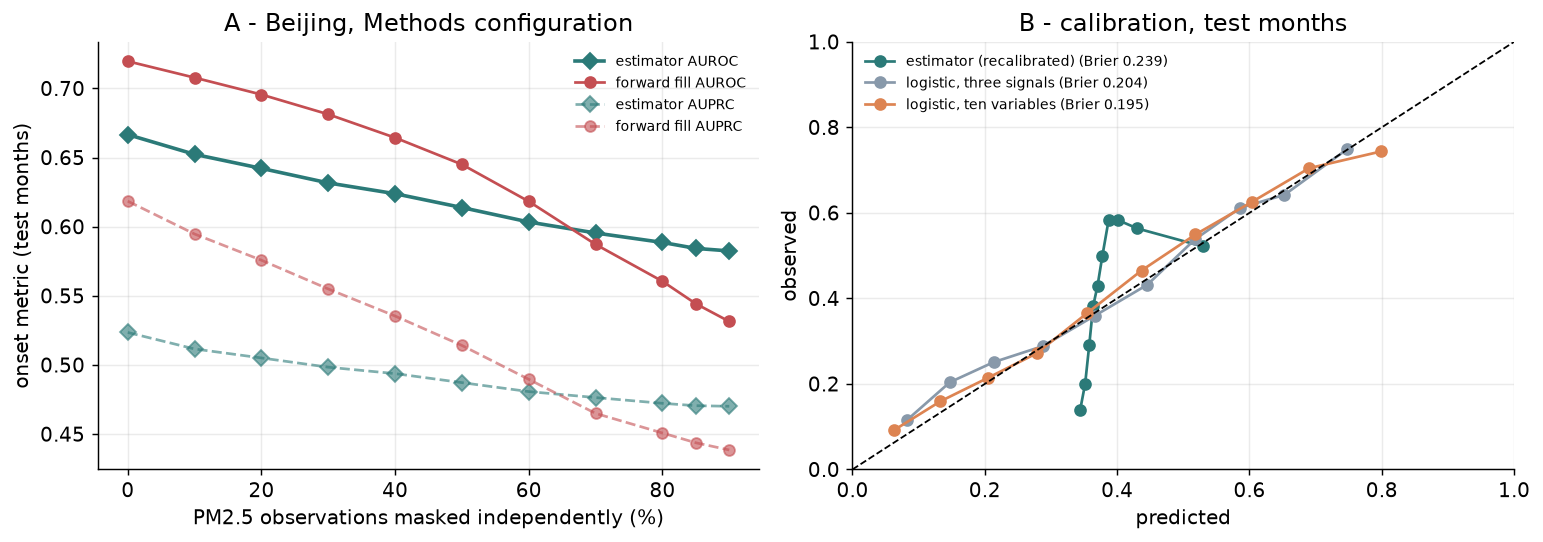


LaTeX rows for tab:beijing:
0\%   & 0.720 & 0.667 & 0.618 & 0.524 \\
10\%  & 0.708 & 0.652 & 0.595 & 0.512 \\
20\%  & 0.696 & 0.642 & 0.576 & 0.505 \\
30\%  & 0.681 & 0.632 & 0.555 & 0.498 \\
40\%  & 0.664 & 0.624 & 0.535 & 0.494 \\
50\%  & 0.645 & 0.614 & 0.514 & 0.487 \\
60\%  & 0.618 & 0.603 & 0.490 & 0.481 \\
70\%  & 0.587 & 0.595 & 0.465 & 0.476 \\
80\%  & 0.561 & 0.589 & 0.451 & 0.472 \\
85\%  & 0.544 & 0.584 & 0.444 & 0.471 \\
90\%  & 0.531 & 0.582 & 0.439 & 0.470 \\

saved to ../outputs/study24_beijing_aligned


In [8]:
fig,ax=plt.subplots(1,2,figsize=(12,4.3))
x=rob.dropout*100
ax[0].plot(x,rob.est_AUROC,"D-",color="#2b7a78",lw=2,label="estimator AUROC")
ax[0].plot(x,rob.LOCF_AUROC,"o-",color="#C44E52",label="forward fill AUROC")
ax[0].plot(x,rob.est_AUPRC,"D--",color="#2b7a78",alpha=.6,label="estimator AUPRC")
ax[0].plot(x,rob.LOCF_AUPRC,"o--",color="#C44E52",alpha=.6,label="forward fill AUPRC")
ax[0].set_xlabel("PM2.5 observations masked independently (%)"); ax[0].set_ylabel("onset metric (test months)")
ax[0].set_title("A - Beijing, Methods configuration"); ax[0].legend(frameon=False,fontsize=8)
def rel(p,yy,nb=10):
    b=pd.qcut(p,nb,duplicates="drop"); grp=pd.DataFrame({"p":p,"y":yy}).groupby(b,observed=True); return grp.p.mean().values,grp.y.mean().values
for p,lab,c in [(p_est,"estimator (recalibrated)","#2b7a78"),(p_l3,"logistic, three signals","#8899AA"),(p_l10,"logistic, ten variables","#DD8452")]:
    xp,yp=rel(p,y_te); ax[1].plot(xp,yp,"-o",label=f"{lab} (Brier {brier(p,y_te):.3f})",color=c)
ax[1].plot([0,1],[0,1],"k--",lw=1); ax[1].set_xlim(0,1); ax[1].set_ylim(0,1)
ax[1].set_xlabel("predicted"); ax[1].set_ylabel("observed"); ax[1].set_title("B - calibration, test months"); ax[1].legend(frameon=False,fontsize=8)
plt.tight_layout(); plt.savefig(OUT/"s24_fig1_beijing.png",bbox_inches="tight"); plt.show()

# rows for Table tab:beijing (Dropout & FF AUROC & Est AUROC & FF AUPRC & Est AUPRC)
print("\nLaTeX rows for tab:beijing:")
for _,r in rob.iterrows():
    lab=f"{r.dropout*100:.0f}\\%"
    print(f"{lab:5s} & {r.LOCF_AUROC:.3f} & {r.est_AUROC:.3f} & {r.LOCF_AUPRC:.3f} & {r.est_AUPRC:.3f} \\\\")
print("\nsaved to",OUT)

## (D) Which change moves the result: one change at a time, complete data, test months

Starts from the submitted configuration and applies the changes in sequence, so the difference between (A) and (B)
can be attributed. S0 must reproduce the test-month row of (A) and S5 the row of (B); both are checks.
The filter below is the study18 implementation generalised to a list of (signal, orientation, weight), with the two
transition matrices precomputed; it is the same model as the estimator above.

In [9]:
A_LO,A_HI=np.zeros((K,K)),np.zeros((K,K))
for A_,pdn in [(A_LO,0.05),(A_HI,0.15)]:
    for k in range(K):
        up=0.25 if k<K-1 else 0; dn=pdn if k>0 else 0; A_[k,k]=1-up-dn
        if k<K-1: A_[k,k+1]=up
        if k>0: A_[k,k-1]=dn
def twin_cfg(Z,cfg):
    n=len(next(iter(Z.values()))); prior=np.exp(-3*np.arange(K)); logb=np.log(prior/prior.sum()+1e-12); risk=np.empty(n)
    cols=[(Z[v],o,w) for v,o,w in cfg]
    for t in range(n):
        b=np.exp(logb-logb.max()); b/=b.sum(); el=(b*LEV_O).sum()
        logbp=np.log(b@(A_LO if el>0.4 else A_HI)+1e-12); ll=np.zeros(K)
        for zv,o,w in cols:
            z=zv[t]
            if np.isnan(z): continue
            ll+=w*lgv_old(z*o)
        logt=logbp+ll; logb=logt-(logt.max()+np.log(np.exp(logt-logt.max()).sum())); risk[t]=float((np.exp(logb)*LEV_O).sum())
    return risk
ZP={st:{c:zcol_old(g,c) for c in ALL} for st,g in stations.items()}     # pooled, full record (submitted)
ZS={st:d["z"] for st,d in ST.items()}                                    # per station, training months
OLD10=[(c,DIR_OLD[c],W_OLD[c]) for c in ALL]
steps=[
 ("S0 submitted configuration",                          ZP, OLD10),
 ("S1 per-station training-month normalisation",         ZS, OLD10),
 ("S2 drop temperature and pressure (zero orientation)", ZS, [x for x in OLD10 if x[0] not in ("TEMP","PRES")]),
 ("S3 drop dew point, add temperature with -1",          ZS, [x for x in OLD10 if x[0] not in ("TEMP","PRES","DEWP")]+[("TEMP",-1,0.8)]),
 ("S4 drop the five other pollutants",                   ZS, [("PM2.5",1,1.4),("WSPM",-1,0.8),("TEMP",-1,0.8)]),
 ("S5 Methods weights 1.0/0.5/0.4 (= Methods config.)",  ZS, [("PM2.5",1,1.0),("WSPM",-1,0.5),("TEMP",-1,0.4)]),
 ("reference: PM2.5 only",                               ZS, [("PM2.5",1,1.0)]),
]
abl=[]
for lab,Z,cfg in steps:
    E,C,Y=[],[],[]
    for st,d in ST.items():
        risk=twin_cfg(Z[st],cfg); cur=ffill(Z[st]["PM2.5"])
        for t,y in d["rows_te"]:
            E.append(risk[t]); C.append(cur[t] if not np.isnan(cur[t]) else 0.0); Y.append(y)
    abl.append(dict(step=lab,signals=", ".join(f"{v}({o:+d},{w})" for v,o,w in cfg),
                    est_AUROC=auc(E,Y),est_AUPRC=apr(E,Y),LOCF_AUROC=auc(C,Y),LOCF_AUPRC=apr(C,Y)))
    print(f"{lab:52s} estimator {abl[-1]['est_AUROC']:.3f} (AUPRC {abl[-1]['est_AUPRC']:.3f}) | forward fill {abl[-1]['LOCF_AUROC']:.3f}")
ABL=pd.DataFrame(abl); ABL.to_csv(OUT/"s24_ablation.csv",index=False)
print("\nchecks: S0 should equal the test-month row of (A); S5 should equal the Methods row of (B).")

S0 submitted configuration                           estimator 0.717 (AUPRC 0.622) | forward fill 0.729
S1 per-station training-month normalisation          estimator 0.710 (AUPRC 0.609) | forward fill 0.720
S2 drop temperature and pressure (zero orientation)  estimator 0.708 (AUPRC 0.602) | forward fill 0.720
S3 drop dew point, add temperature with -1           estimator 0.728 (AUPRC 0.611) | forward fill 0.720
S4 drop the five other pollutants                    estimator 0.663 (AUPRC 0.526) | forward fill 0.720
S5 Methods weights 1.0/0.5/0.4 (= Methods config.)   estimator 0.667 (AUPRC 0.524) | forward fill 0.720
reference: PM2.5 only                                estimator 0.626 (AUPRC 0.485) | forward fill 0.720

checks: S0 should equal the test-month row of (A); S5 should equal the Methods row of (B).


## (E) Exploratory: the six pollutants as observation channels, under PM2.5 dropout

Step S3 of (D) keeps the six pollutants (+1, weight 1.4) and uses wind speed and temperature with the Methods
orientation (-1, weight 0.8), without the zero-orientation terms. It is defined **after** seeing (D), so it is an
exploratory variant, not a pre-specified configuration; it is reported here only so the decision on how to present
Beijing can be made with the full picture. Only PM2.5 is masked (same seeds, so the masks equal those of (B));
the other pollutants stay observed, as when one analyser fails at a multi-pollutant station.

In [10]:
CFG_S3=steps[3][2]
def run_level_cfg(frac,seed,cfg):
    rng=np.random.default_rng(seed); E=[];C=[];Y=[]
    for st,d in ST.items():
        Z=dict(ZS[st]); zpm=Z["PM2.5"].copy()
        if frac>0: zpm[rng.random(len(zpm))<frac]=np.nan
        Z["PM2.5"]=zpm; risk=twin_cfg(Z,cfg); cur=ffill(zpm)
        for t,y in d["rows_te"]:
            E.append(risk[t]); C.append(cur[t] if not np.isnan(cur[t]) else 0.0); Y.append(y)
    return np.array(E),np.array(C),np.array(Y,int)
resE=[]
for fr in FR:
    seeds=[30] if fr==0 else [30,31,32]; M=[]; dd=lo=hi=np.nan
    for s in seeds:
        E,C,Y=run_level_cfg(fr,s,CFG_S3); M.append((auc(E,Y),apr(E,Y),auc(C,Y),apr(C,Y)))
        if s==30 and fr in (0.0,0.5,0.85): dd,lo,hi=paired_boot(E,C,Y)
    m=np.mean(M,axis=0); mb=rob.set_index("dropout").loc[fr]
    resE.append(dict(dropout=fr,multi_AUROC=m[0],multi_AUPRC=m[1],LOCF_AUROC=m[2],LOCF_AUPRC=m[3],AUROC_adv=m[0]-m[2],
                     adv_seed30=dd,adv_lo95=lo,adv_hi95=hi,methods_AUROC=mb.est_AUROC))
    ci="" if np.isnan(lo) else f" [seed30 CI {lo:+.3f},{hi:+.3f}]"
    print(f"{fr*100:3.0f}% | multi-pollutant {m[0]:.3f} (AUPRC {m[1]:.3f}) | forward fill {m[2]:.3f} | adv {m[0]-m[2]:+.3f}{ci} | Methods config {mb.est_AUROC:.3f}")
RE=pd.DataFrame(resE); RE.to_csv(OUT/"s24_multipollutant_dropout.csv",index=False)

  0% | multi-pollutant 0.728 (AUPRC 0.611) | forward fill 0.720 | adv +0.009 [seed30 CI +0.003,+0.014] | Methods config 0.667
 10% | multi-pollutant 0.725 (AUPRC 0.609) | forward fill 0.708 | adv +0.018 | Methods config 0.652
 20% | multi-pollutant 0.724 (AUPRC 0.608) | forward fill 0.696 | adv +0.028 | Methods config 0.642
 30% | multi-pollutant 0.722 (AUPRC 0.606) | forward fill 0.681 | adv +0.040 | Methods config 0.632
 40% | multi-pollutant 0.721 (AUPRC 0.605) | forward fill 0.664 | adv +0.056 | Methods config 0.624
 50% | multi-pollutant 0.719 (AUPRC 0.604) | forward fill 0.645 | adv +0.074 [seed30 CI +0.064,+0.080] | Methods config 0.614
 60% | multi-pollutant 0.718 (AUPRC 0.603) | forward fill 0.618 | adv +0.100 | Methods config 0.603
 70% | multi-pollutant 0.717 (AUPRC 0.602) | forward fill 0.587 | adv +0.130 | Methods config 0.595
 80% | multi-pollutant 0.718 (AUPRC 0.602) | forward fill 0.561 | adv +0.157 | Methods config 0.589
 85% | multi-pollutant 0.718 (AUPRC 0.601) | for

## Reading this for the manuscript

Send the outputs of (A), (B) and (C) before changing any text. What changes after this run:
- Table `tab:beijing` (all rows) and its caption (PM2.5 masked, test months).
- The Results paragraph starting "Episode onset is forecastable on the Beijing benchmark".
- The Beijing calibration numbers in the Results and in the response letter (Reviewer 2, Comment 24).
- The Beijing clauses in the Conclusions and Limitations, if the direction of any result changes.
- The Methods sentence that describes the Beijing configuration.

Unchanged: the onset labels and base rates (threshold, aggregation and horizon are the same), and all Nordic and
North China Plain results.